# 💳 Taller de Clustering — Parte 2: Tarjetas de crédito

Notebook de trabajo: solo contiene las fases ya vistas (ver [`learn_roadmap.md`](learn_roadmap.md)).

## ✅ Fase 07 · Comprensión del problema y de los datos — ya vista

> **Resumen fase 07:** **8.950 clientes × 18 columnas**, todas **numéricas** salvo `CUST_ID` (una **matrícula**: un valor distinto por cliente, no sirve para agrupar). **No hay etiqueta**. Escalas **muy distintas** (0–1 frente a miles) y **colas largas** (media ≫ mediana). Nulos: `CREDIT_LIMIT` (**1**) y `MINIMUM_PAYMENTS` (**313**). Búsqueda sistemática: 0 negativos y **8 frecuencias > 1** (imposibles).

▶️ **Ejecuta primero la celda plegada de abajo** (o usa *Run All*): crea `df`, `X`, `y`… que necesita la fase actual. Pulsa `…` para ver su código.

In [1]:
%matplotlib inline
# Hace que los gráficos aparezcan dentro del notebook
import warnings
warnings.filterwarnings("ignore")  # oculta avisos para que la salida quede limpia

import pandas as pd              # DataFrame: la "hoja de cálculo" con la que trabajamos
import numpy as np               # cálculo numérico
import seaborn as sns            # gráficos estadísticos con poco código
import matplotlib.pyplot as plt  # base de todos los gráficos

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42  # semilla fija: así los resultados se pueden repetir

df = pd.read_csv("docs/workshop/data/credit_card.csv")
df.head()

# ¿Cuántos clientes (filas) y cuántas variables (columnas)?
df.shape

# Tipos de datos: ¿hay texto o todo es número?
print(df.dtypes.value_counts())
df.dtypes

print("Valores distintos en CUST_ID:", df["CUST_ID"].nunique(), "de", len(df), "filas")
df["CUST_ID"].head()

# .T gira la tabla: una fila por variable, más fácil de leer
df.describe().T.round(2)

numericas = df.drop(columns="CUST_ID")
print("Valores negativos en todo el dataset:", (numericas < 0).sum().sum())

frecuencias = [c for c in df.columns if c.endswith("_FREQUENCY")]
print("\nFrecuencias mayores que 1:")
print((df[frecuencias] > 1).sum())

# ¿Quiénes son esos clientes con frecuencia > 1?
df.loc[df["CASH_ADVANCE_FREQUENCY"] > 1,
       ["CUST_ID", "CASH_ADVANCE_FREQUENCY", "CASH_ADVANCE_TRX", "TENURE"]]

# Nulos por columna (solo las que tengan alguno)
nulos = df.isnull().sum()
nulos[nulos > 0]

float64    14
int64       3
str         1
Name: count, dtype: int64
Valores distintos en CUST_ID: 8950 de 8950 filas
Valores negativos en todo el dataset: 0

Frecuencias mayores que 1:
BALANCE_FREQUENCY                   0
PURCHASES_FREQUENCY                 0
ONEOFF_PURCHASES_FREQUENCY          0
PURCHASES_INSTALLMENTS_FREQUENCY    0
CASH_ADVANCE_FREQUENCY              8
dtype: int64


CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64

## ✅ Fase 08 · Preparación de los datos — ya vista

> **Resumen fase 08:** quitamos `CUST_ID`, **recortamos a 1** las 8 frecuencias imposibles y rellenamos los nulos con la **mediana** (no se deja arrastrar por los extremos: en `MINIMUM_PAYMENTS` media 864 vs mediana 312). Las variables de dinero tienen **colas largas**. Con **`StandardScaler`** todas quedan con **media 0 y desviación 1**: antes, unas pocas variables grandes decidían casi toda la distancia; después, todas pesan.

▶️ **Ejecuta primero la celda plegada de abajo** (o usa *Run All*): crea `df`, `X`, `y`… que necesita la fase actual. Pulsa `…` para ver su código.

Frecuencias > 1 tras corregir: 0
CREDIT_LIMIT       media:   4494.4   mediana:   3000.0   máximo:   30000.0
MINIMUM_PAYMENTS   media:    864.2   mediana:    312.3   máximo:   76406.2
Nulos que quedan: 0


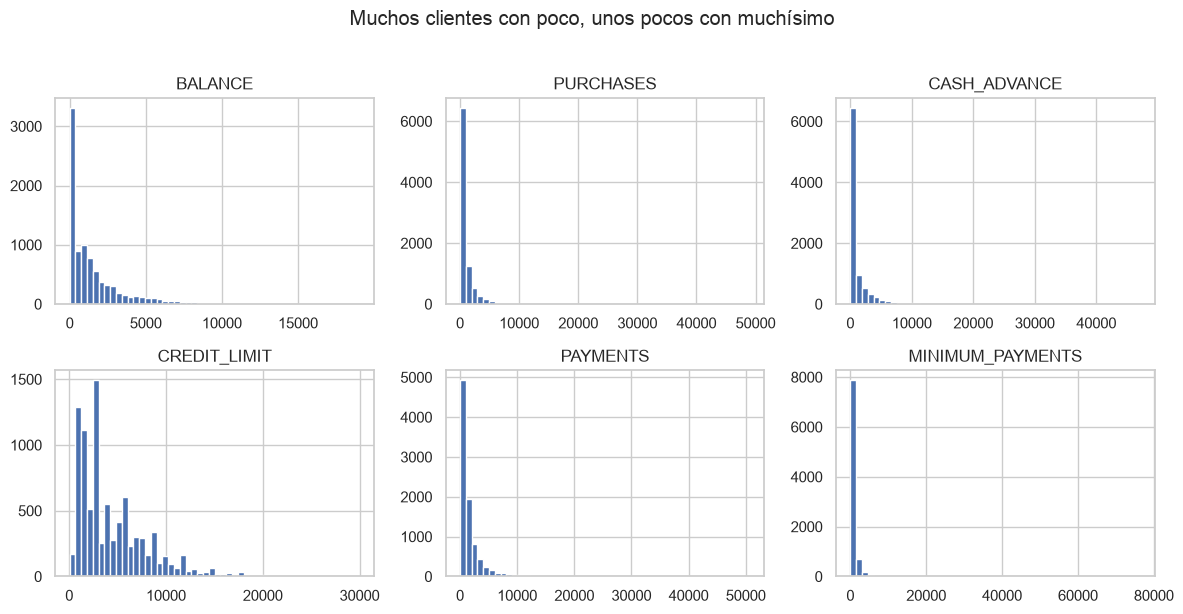

,% sin escalar,% escalado
CREDIT_LIMIT,39.8,8.3
BALANCE,15.4,6.8
PAYMENTS,13.3,3.4
CASH_ADVANCE,11.2,4.5
PURCHASES,7.7,2.5
MINIMUM_PAYMENTS,5.4,2.4
ONEOFF_PURCHASES,4.2,2.6
INSTALLMENTS_PURCHASES,3.0,3.5
PURCHASES_TRX,0.0,3.7
PRC_FULL_PAYMENT,0.0,8.3


In [2]:
df = df.drop(columns="CUST_ID")
df.shape

df["CASH_ADVANCE_FREQUENCY"] = df["CASH_ADVANCE_FREQUENCY"].clip(upper=1)
print("Frecuencias > 1 tras corregir:", (df["CASH_ADVANCE_FREQUENCY"] > 1).sum())

for col in ["CREDIT_LIMIT", "MINIMUM_PAYMENTS"]:
    print(f"{col:17}  media: {df[col].mean():8.1f}   mediana: {df[col].median():8.1f}   máximo: {df[col].max():9.1f}")

for col in ["CREDIT_LIMIT", "MINIMUM_PAYMENTS"]:
    df[col] = df[col].fillna(df[col].median())

print("Nulos que quedan:", df.isnull().sum().sum())

cols = ["BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS", "MINIMUM_PAYMENTS"]
df[cols].hist(bins=50, figsize=(12, 6), layout=(2, 3))
plt.suptitle("Muchos clientes con poco, unos pocos con muchísimo", y=1.02)
plt.tight_layout(); plt.show()

# Asimetría (skew): 0 = simétrica; cuanto más alta, más larga la cola derecha
df.skew().sort_values(ascending=False).round(1).head(6)

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(df)                # array escalado: lo usaremos en todas las fases siguientes
X_df = pd.DataFrame(X, columns=df.columns)

# Comprobación: media 0 y desviación 1 en todas las columnas
X_df.agg(["mean", "std"]).T.round(2).head(6)

rng = np.random.default_rng(RANDOM_STATE)
i, j = rng.integers(0, len(df), 2000), rng.integers(0, len(df), 2000)   # 2000 parejas al azar

def aporte_por_variable(datos):
    d2 = (datos[i] - datos[j]) ** 2                          # lo que suma cada variable a la distancia²
    return (d2 / d2.sum(axis=1, keepdims=True)).mean(axis=0) * 100

pd.DataFrame({"% sin escalar": aporte_por_variable(df.values),
              "% escalado": aporte_por_variable(X)},
             index=df.columns).round(1).sort_values("% sin escalar", ascending=False)

## ✅ Fase 09 · Exploración: ¿se ven grupos? — ya vista

> **Resumen fase 09:** PC1 guarda el 27 % y PC2 el 20 %; para el **80 %** hacen falta **7 de 17** componentes, sin codo claro. **PC1 = compras** y **PC2 = efectivo/saldo**. En 2D se ve **una nube continua** con brazos, **sin grupos separados**: los segmentos serán **zonas** de la nube, no islas.

▶️ **Ejecuta primero la celda plegada de abajo** (o usa *Run All*): crea `df`, `X`, `y`… que necesita la fase actual. Pulsa `…` para ver su código.

Componentes para el 80 % de la varianza: 7 de 17


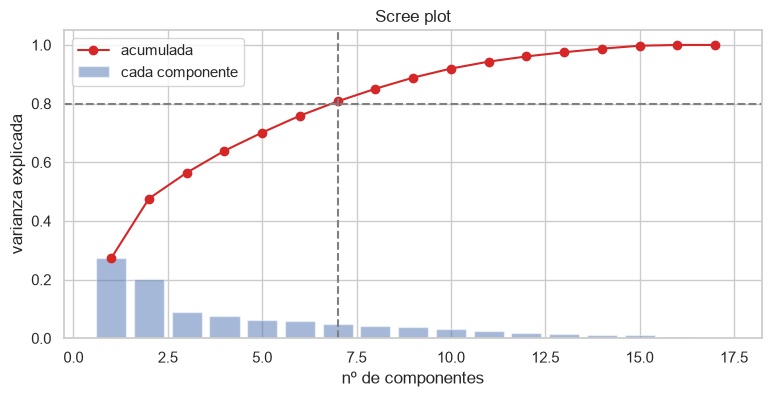

PC1: {'PURCHASES': 0.41, 'PURCHASES_TRX': 0.39, 'ONEOFF_PURCHASES': 0.35, 'INSTALLMENTS_PURCHASES': 0.34, 'PURCHASES_FREQUENCY': 0.32} 

PC2: {'CASH_ADVANCE': 0.44, 'CASH_ADVANCE_FREQUENCY': 0.43, 'CASH_ADVANCE_TRX': 0.42, 'BALANCE': 0.4, 'PAYMENTS': 0.26} 



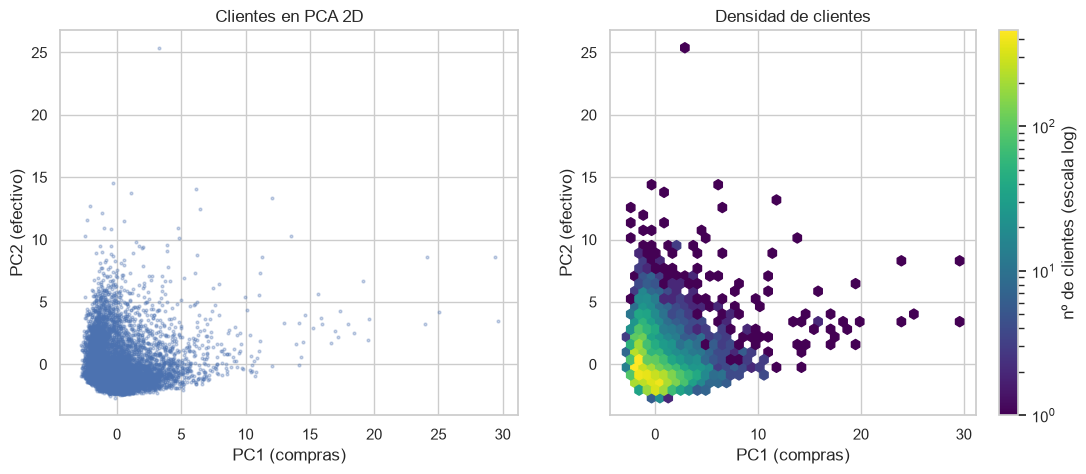

In [3]:
from sklearn.decomposition import PCA

pca_full = PCA(random_state=RANDOM_STATE).fit(X)
varianza = pca_full.explained_variance_ratio_
acumulada = varianza.cumsum()

n80 = np.argmax(acumulada >= 0.80) + 1        # primera componente que llega al 80 %
print(f"Componentes para el 80 % de la varianza: {n80} de {X.shape[1]}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(1, len(varianza) + 1), varianza, alpha=0.5, label="cada componente")
ax.plot(range(1, len(acumulada) + 1), acumulada, "o-", color="tab:red", label="acumulada")
ax.axhline(0.80, ls="--", color="gray"); ax.axvline(n80, ls="--", color="gray")
ax.set(xlabel="nº de componentes", ylabel="varianza explicada", title="Scree plot")
ax.legend(); plt.show()

pd.DataFrame({"varianza": varianza, "acumulada": acumulada},
             index=range(1, len(varianza) + 1)).round(3).head(8)

pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit(X)
X_pca = pca2.transform(X)

for k in range(2):
    pesos = pd.Series(pca2.components_[k], index=df.columns)
    top = pesos.reindex(pesos.abs().sort_values(ascending=False).index).head(5).round(2)
    print(f"PC{k+1}:", top.to_dict(), "\n")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Izquierda: cada cliente un punto (sin colores: no hay etiqueta)
ax[0].scatter(X_pca[:, 0], X_pca[:, 1], s=4, alpha=0.3)
ax[0].set(title="Clientes en PCA 2D", xlabel="PC1 (compras)", ylabel="PC2 (efectivo)")

# Derecha: densidad (hexágonos): ¿dónde se amontonan?
hb = ax[1].hexbin(X_pca[:, 0], X_pca[:, 1], gridsize=40, bins="log", cmap="viridis")
ax[1].set(title="Densidad de clientes", xlabel="PC1 (compras)", ylabel="PC2 (efectivo)")
fig.colorbar(hb, ax=ax[1], label="nº de clientes (escala log)")
plt.show()

## Fase 10 · Modelado: cortar la nube en segmentos

**Objetivo:** aplicar los **mismos 4 algoritmos** que en las setas (K-Means, Aglomerativo, GMM, DBSCAN) a los clientes. Ahora **no hay etiqueta**: elegimos k **solo** con las métricas internas y lo que tenga sentido para negocio.

Trabajamos sobre `X` (las **17 variables escaladas**): son pocas, no hace falta reducir con PCA.

### K-Means: ¿cuántos segmentos? Codo + silueta

*Recuerda (fase 04):* la **inercia** siempre baja al subir k (buscamos el **codo**); la **silueta** compara cada cliente con su grupo y con el vecino (**más alta = mejor**).

![Método del codo](assets/taller/f04-codo.png)

![Silueta](assets/taller/f04-silueta.png)

*Fuente: diapositivas del bootcamp «Aprendizaje No Supervisado» (FactoriaF5).*

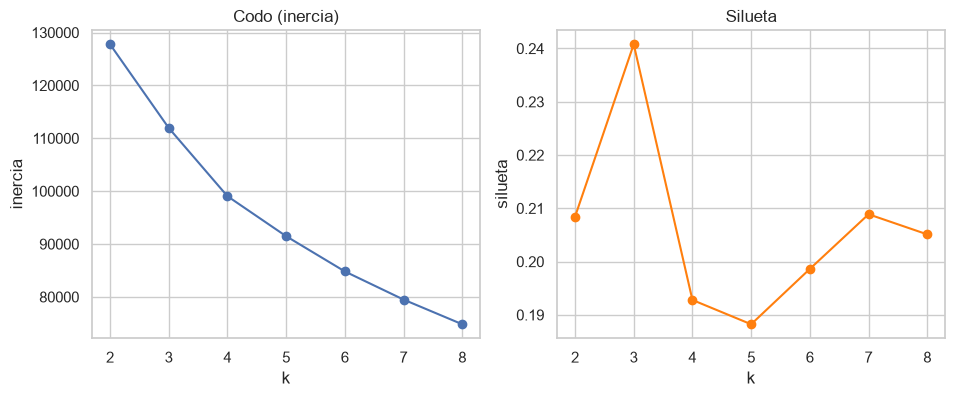

Mejor k por silueta: 3


,k,inercia,silueta,tamaños
0,2,127780.646,0.208,"[5243, 3707]"
1,3,111956.982,0.241,"[6117, 1598, 1235]"
2,4,99050.255,0.193,"[3977, 3365, 1199, 409]"
3,5,91480.462,0.188,"[3919, 2410, 1390, 1145, 86]"
4,6,84816.634,0.199,"[3041, 2229, 1315, 1310, 969, 86]"
5,7,79493.293,0.209,"[2841, 2046, 1266, 1188, 893, 630, 86]"
6,8,74825.318,0.205,"[2766, 2672, 1197, 885, 721, 640, 39, 30]"


In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 9)
inercias, siluetas, tamaños = [], [], []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X, km.labels_, sample_size=4000, random_state=RANDOM_STATE))
    tamaños.append(sorted(np.bincount(km.labels_), reverse=True))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(k_values, inercias, "o-"); ax[0].set(title="Codo (inercia)", xlabel="k", ylabel="inercia")
ax[1].plot(k_values, siluetas, "o-", color="tab:orange"); ax[1].set(title="Silueta", xlabel="k", ylabel="silueta")
plt.show()

best_k = list(k_values)[int(np.argmax(siluetas))]
print("Mejor k por silueta:", best_k)
pd.DataFrame({"k": k_values, "inercia": inercias, "silueta": siluetas, "tamaños": tamaños}).round(3)

**Lectura:**
- La **silueta máxima** está en **k = 3** (≈ 0,24). Es **baja** (en las setas era 0,26 con k = 2 y subía hasta 0,48): normal en una **nube continua** (fase 09).
- El **codo** es suave, pero la inercia baja menos a partir de k = 3–4.
- Mira los **tamaños**: desde k = 5 aparece un grupo de solo **86 clientes** (y con k = 8, de 30–39). Son **extremos**, no un segmento útil para una campaña.

👉 Elegimos **k = 3**: mejor silueta **y** grupos con tamaño suficiente para actuar.

> 📖 **En los libros**
>
> - **Primer libro:** K-Means **siempre corta** el espacio en zonas, haya grupos o no. Con las **coordenadas de California** (una nube continua de 20.640 distritos) coloca **10 centros** y los usa como zonas útiles: igual que haremos con los clientes. Y avisa: K-Means **prefiere grupos de tamaño parecido**; en una foto de una mariquita, el rojo (pocos píxeles) solo consigue su propio grupo con **k ≥ 8**.
> - **Segundo libro:** con 20 usuarios el codo es claro (k = 3) porque **sí** hay grupos separados; no trata nubes continuas.

In [5]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit(X)
clusters_km = kmeans.labels_

tam = pd.Series(clusters_km).value_counts().sort_index()
pd.DataFrame({"clientes": tam, "%": (tam / len(X) * 100).round(1)})

,clientes,%
0,1598,17.9
1,6117,68.3
2,1235,13.8


Un segmento **grande (~68 %)** y dos **pequeños (~18 % y ~14 %)**. En la fase 12 descubriremos **quiénes son** cada uno.

### Aglomerativo + dendrograma

*Recuerda:* une a los más cercanos paso a paso; el **dendrograma** muestra a qué **altura** se unen los grupos.

![Cómo leer un dendrograma](assets/taller/f04-dendrograma.png)

*Fuente: diapositivas del bootcamp «Aprendizaje No Supervisado» (FactoriaF5).*

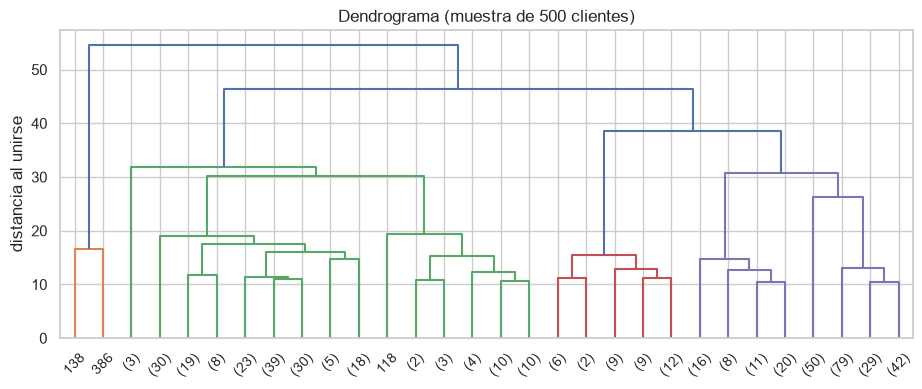

0    2909
1    4848
2    1193
Name: count, dtype: int64

In [6]:
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering

rng = np.random.default_rng(RANDOM_STATE)
muestra = X[rng.choice(len(X), size=500, replace=False)]

plt.figure(figsize=(11, 4))
dendrogram(linkage(muestra, method="ward"), truncate_mode="lastp", p=30)
plt.title("Dendrograma (muestra de 500 clientes)"); plt.ylabel("distancia al unirse")
plt.show()

clusters_ag = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X)
pd.Series(clusters_ag).value_counts().sort_index()

### GMM: segmentos con probabilidad

*Recuerda:* cada grupo es una **campana** (puede ser alargada) y cada cliente recibe una **probabilidad** de pertenecer a cada grupo.

![GMM](assets/taller/f04-gmm.png)

*Fuente: diapositivas del bootcamp «Aprendizaje No Supervisado» (FactoriaF5).*

In [7]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=3, random_state=RANDOM_STATE).fit(X)
clusters_gmm = gmm.predict(X)
probs = gmm.predict_proba(X)

print(pd.Series(clusters_gmm).value_counts().sort_index())
print("Clientes con duda (ningún grupo > 90 %):", (probs.max(axis=1) < 0.9).sum())

0    2606
1    2934
2    3410
Name: count, dtype: int64
Clientes con duda (ningún grupo > 90 %): 81


GMM reparte de forma **muy distinta** (tres grupos de tamaño parecido): con **colas largas**, las campanas se adaptan a formas que K-Means (grupos redondos) no ve. ¿Quién tiene razón? **Sin etiqueta no hay árbitro**: lo veremos en la fase 11 con las métricas internas.

> 📖 **En los libros**
>
> - **Primer libro:** con 3 grupos **alargados y de distinto tamaño**, K-Means **corta el 25 %** del grupo central y se lo da al vecino; GMM, con campanas alargadas, los separa bien. GMM tiene 4 formas de campana (`covariance_type`): `"full"` (cualquier forma, por defecto), `"tied"` (todas iguales), `"diag"` (alineadas con los ejes) y `"spherical"` (redondas).
> - **Segundo libro:** no trata GMM.

### DBSCAN: ¿hay zonas densas separadas?

*Recuerda:* **`eps`** = radio de vecindad; **`min_samples`** = vecinos para ser núcleo; el resto es **ruido (−1)**. Lo probamos sobre el **PCA 2D** de la fase 09 con varios `eps`.

![DBSCAN](assets/taller/f04-dbscan.png)

*Fuente: diapositivas del bootcamp «Aprendizaje No Supervisado» (FactoriaF5).*

In [8]:
from sklearn.cluster import DBSCAN

for eps in [0.1, 0.2, 0.3, 0.5, 1.0]:
    labels = DBSCAN(eps=eps, min_samples=10).fit_predict(X_pca)
    n_grupos = len(set(labels)) - (1 if -1 in labels else 0)
    mayor = np.bincount(labels[labels >= 0]).max()
    print(f"eps={eps:<4} -> grupos: {n_grupos:3d}   ruido: {(labels == -1).sum():5d}   grupo mayor: {mayor} clientes")

eps=0.1  -> grupos:  25   ruido:  2632   grupo mayor: 5918 clientes
eps=0.2  -> grupos:  13   ruido:   966   grupo mayor: 7844 clientes
eps=0.3  -> grupos:   4   ruido:   483   grupo mayor: 8426 clientes
eps=0.5  -> grupos:   3   ruido:   247   grupo mayor: 8682 clientes


eps=1.0  -> grupos:   1   ruido:    81   grupo mayor: 8869 clientes


**Lectura:** da igual el `eps`: siempre hay **un grupo gigante** (de 5.900 a **8.869** clientes) más algunos grupitos y ruido. Con `eps = 1.0`: **1 solo grupo + 81 clientes de ruido**.

DBSCAN busca **zonas densas separadas por huecos**; en una **nube continua no hay huecos**, así que lo ve todo como **un solo grupo**. Lo útil de DBSCAN aquí es otra cosa: el **ruido** señala a los clientes **más extremos** (lo retomaremos con Isolation Forest).

> 📖 **En los libros**
>
> - **Primer libro:** DBSCAN brilla con formas raras (las **2 lunas**) y marca el ruido como −1. Pero **falla** cuando los grupos **no están separados por zonas vacías** (nuestro caso) o tienen **densidades distintas** (recomienda **HDBSCAN**), y con muchas dimensiones.
> - **Segundo libro:** la **maldición de la dimensión**: con 10.000 parejas de puntos al azar, al pasar de 1 a **100 dimensiones** la distancia al vecino más cercano se acerca a la distancia **media**: «cerca» y «lejos» dejan de distinguirse. Por eso aquí usamos DBSCAN sobre el PCA 2D.

> **Resumen fase 10:** con `X` (17 variables escaladas), la **silueta máxima** está en **k = 3** (≈ 0,24, baja por ser una nube continua); con k ≥ 5 aparecen grupos de ~86 clientes extremos. **K-Means k = 3**: ~68 % / ~18 % / ~14 %. **Aglomerativo** también da un grupo grande y uno de ~1.200, aunque no idénticos; **GMM** muy distinto (campanas sobre colas largas). **DBSCAN** ve **1 grupo + ruido**: no hay huecos en la nube.